# Deliverable 1: Is the “Martingale” strategy profitable?  

   ![roulette gif](https://media.giphy.com/media/GWS8bXKxphfEI/giphy.gif)

## Explanation of Roulette and the Martingale strategy

First off, let's talk about roulette. It is a gambling game, where a user can bet money to see where a ball will land on a spinning wheel. Once the wheel slows, the ball has three outcomes: land in red, black, or green. There are 18 red spots, 18 black, and 2 green. 

Let's say that a person bets black, and the ball lands on black, when they bet $2, they gain $4 total. If someone bets red, and bet $2, they lose their $2. If ball lands on green, all players lose money, unless they bet on green. 

In the long run, the house gains money from this game, and players lose money. But what if there was a strategy that could allow players to make money in the long run? Let's look at a possible one.

The Martingale strategy essentially has a player pick either red or black. They will only choose one color to bet on for the rest of the trials. If a person bets on red, and the ball lands on red, they gain $1. However, let's say a player bets $1 on red again, and the ball lands on black. The player then doubles up the bet, betting $2. If they lose that, they bet $4, and it lands on red. Then they will bet $1 and so on. 

Let's take a look at a simulation, and see if this makes money over time

## Simulation

Essentially, the code below will have the computer run a bunch of simulations, not actually playing real roulette, the computer randomly chooses whether black, red, or green is picked.

For clarity: B stands for player's budget, or how much money they have at the start. W stands for the winning goal, so say $300. L is the time limit, specifically 200 spins. M is the casino's maximum bet, or the highest amount of money a player is allowed to bet on one spin.

In [5]:
import numpy as np
from itertools import groupby
import matplotlib.pyplot as plt
import pandas as pd

def oneplay(B=200, W=300, L=200, M=100, summary = True):

    # martingale
    def wager(ledger):
        if ledger["outcome"][-1] == 1:
            new_wager = 1
        else:
            new_wager = min(2*ledger["wager"][-1], M, ledger["budget"][-1])
        ledger["wager"].append(new_wager)

    def spin(ledger):
        spin = np.random.binomial(1, p = 18/38)
        ledger["outcome"].append(spin)

    def stop_rule(ledger):
        if ledger["outcome"][-1] == 1:
            ledger["budget"].append(ledger["budget"][-1] + ledger["wager"][-1])
        else:
            ledger["budget"].append(ledger["budget"][-1] - ledger["wager"][-1])
        
        if ledger["budget"][-1] >= W:
            outcome = 1
        elif len(ledger["budget"]) - 1 >= L:
            outcome = -1
        elif ledger["budget"][-1] <= 0:
            outcome = -2
        else:
            outcome = 0
        return outcome

    # ledger
    ledger = {"budget":[B, B], "wager":[0], "outcome":[1]}
    outcome = 0
    while outcome == 0:
        wager(ledger)
        spin(ledger)
        outcome = stop_rule(ledger)

    if summary == False:
        return ledger

    bad_luck = max([len(list(values)) for key, values in groupby(ledger["outcome"]) if key == 0])
        
    summary = {
          "B":B
        , "W":W
        , "L":L
        , "M":M
        , "outcome":outcome
        , "profit":ledger["budget"][-1] - B
        , "n_games":len(ledger["budget"]) - 1
        , "prop_red":np.mean(ledger["outcome"])
        , "bad_luck_streak": bad_luck
    }

    return summary

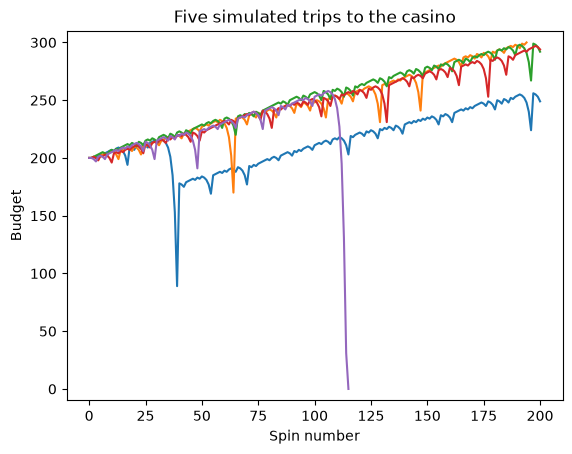

In [9]:
np.random.seed(20545234) 
plt.close()
for i in range(5):
    p1 = oneplay(summary = False)
    plt.plot(p1["budget"])
plt.ylim([-10, 310])
plt.xlabel("Spin number")
plt.ylabel("Budget")
plt.title("Five simulated trips to the casino")
plt.show()

In this visualization, the colors represent seperate, independent trips to the casino. Four out of five of the trips made money, with purple losing money. 

However, while the strategy for those 4 trips makes small amounts of profits that add up, there are a few occassions where the players lose big, with the losing player losing so big they lost it all.

This doesn't tell us enough about whether the strategy works well in the long run among many, independent trials. 5 trips isn't enough to allow a proper conclusion

## 10000 Simulated Trips to the casino

In [10]:
R = 10000
A = [oneplay() for i in range(R)]
B = pd.DataFrame(A)
B.profit.mean().item()

-35.9875

The cell above shows the average profit in over 10,000 simulated trips to the casino. A player on average, loses about 36 dollars, indicating that using the Martingale betting strategy loses money.

This answers the question, that no, the Martingale strategy is not profitable. But what if there was no time limit? What if gamblers were able to stay at the casino forever at the roulette wheel, without having to eat, drink, sleep? Would they still lose money or eventually reach the profit goal?

## No Time Limit

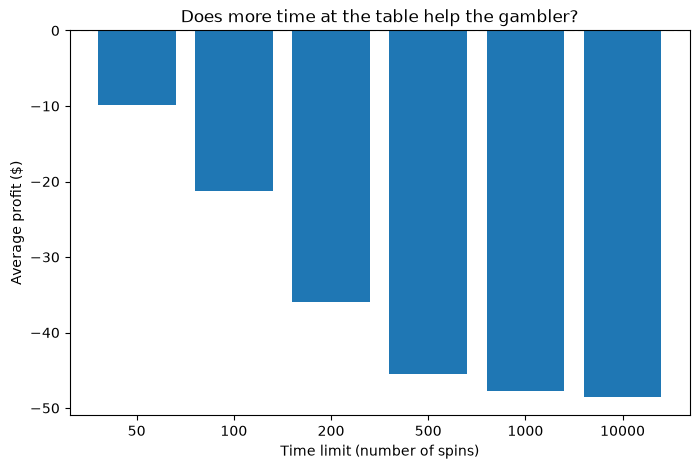

In [12]:
time_limits = [50, 100, 200, 500, 1000, 10000]
avg_profit = []

for L in time_limits:
    trips = pd.DataFrame([oneplay(L=L) for i in range(5000)])
    avg_profit.append(trips.profit.mean())

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar([str(L) for L in time_limits], avg_profit)
ax.axhline(0, color="gray", linestyle="--")
ax.set_xlabel("Time limit (number of spins)")
ax.set_ylabel("Average profit ($)")
ax.set_title("Does more time at the table help the gambler?")
plt.show()

This chart shows that even an extreme amount of time can't save the gambler. It makes things worse, and they lose even more money with the Martingale strategy.

## Conclusion

Do NOT use the Martingale strategy if your goal is to make money. While you might make small bits of money here and there, a losing streak either often leads to reaching the casino bet limit, limiting the ability to get a profit, or just lose it all. 

10,000 simulations show that the gambler will lose an average value of about 36 dollars. Increasing the amount of time the gambler has doesn't even help either, it makes things worse.